In [15]:
import json

with open(
    "../data/processed/fraud_threshold.json",
    "r"
) as f:
    threshold_config = json.load(f)

BEST_THRESHOLD = threshold_config["threshold"]

print("Loaded threshold:", BEST_THRESHOLD)

Loaded threshold: 0.99


In [16]:
import joblib
import shap

xgb_model = joblib.load(
    "../data/processed/xgb_fraud_model.pkl"
)

print(type(xgb_model))

<class 'xgboost.sklearn.XGBClassifier'>


In [17]:
import shap
import pandas as pd
import numpy as np

train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/validation.csv")
test_df = pd.read_csv("../data/processed/test.csv")

TARGET = "isFraud"
ID_COLUMNS = ["nameOrig", "nameDest"]

X_train = train_df.drop(columns=[TARGET] + ID_COLUMNS)
y_train = train_df[TARGET]

X_test = test_df.drop(columns=[TARGET] + ID_COLUMNS)
y_test = test_df[TARGET]

X_train = pd.get_dummies(
    X_train,
    columns=["type"],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["type"],
    dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [18]:
explainer = shap.TreeExplainer(xgb_model)
explainer = shap.TreeExplainer(xgb_model)

print("SHAP explainer created successfully.")

SHAP explainer created successfully.


In [19]:
X_test_sample = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=42
)

shap_values = explainer(
    X_test_sample
)

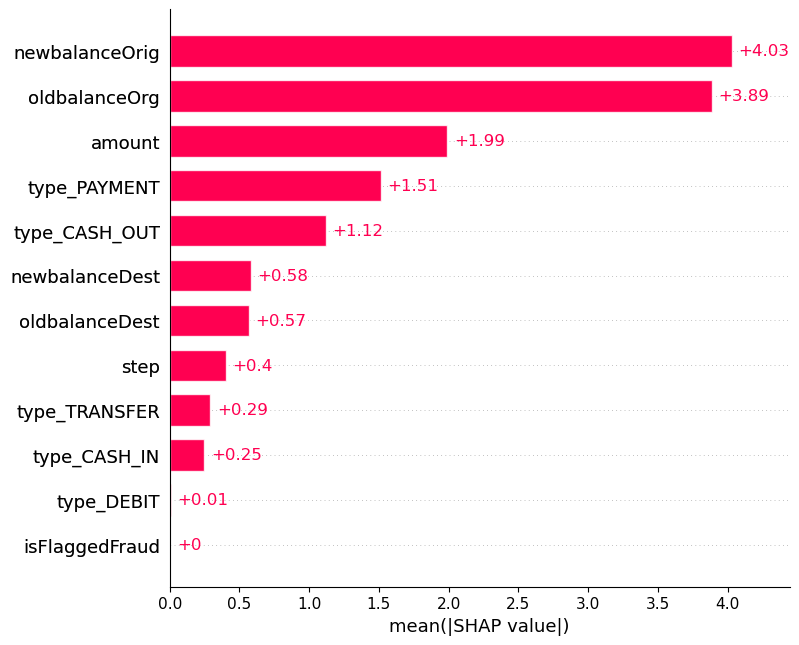

In [20]:
shap.plots.bar(
    shap_values,
    max_display=15
)

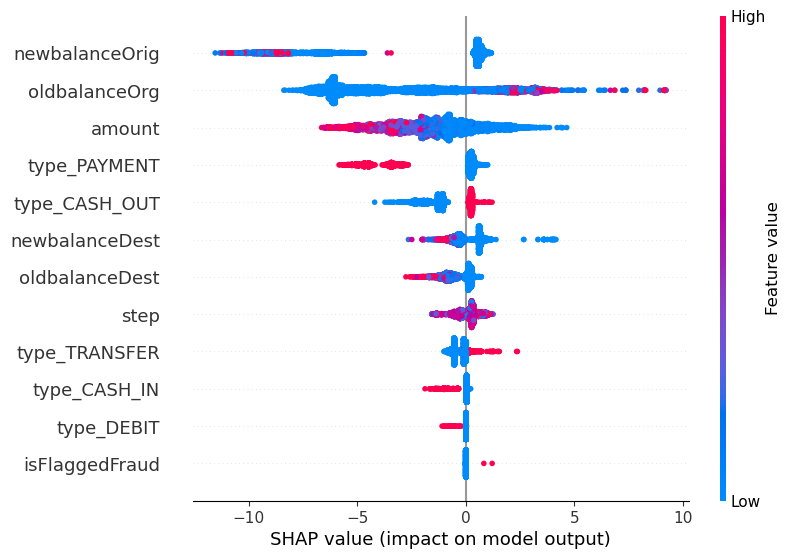

In [21]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

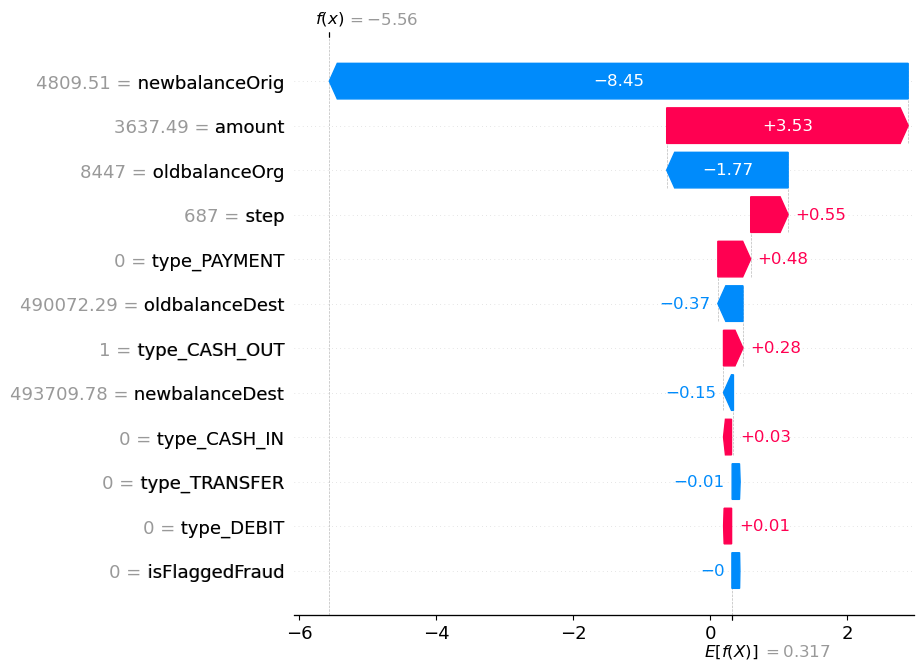

In [22]:
transaction_index = 0

shap.plots.waterfall(
    shap_values[transaction_index],
    max_display=15
)

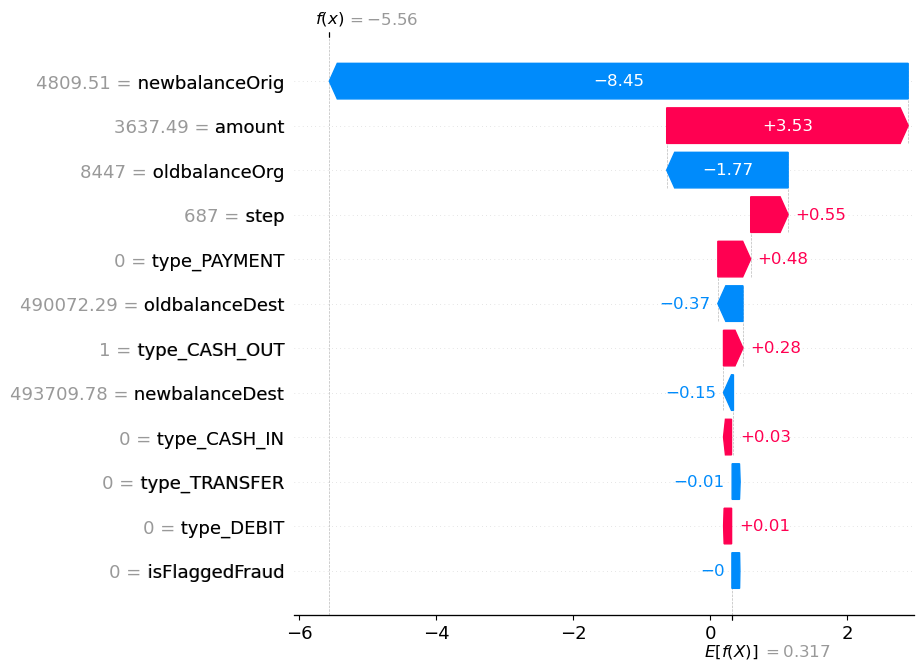

In [23]:
transaction_index = 0

shap.plots.waterfall(
    shap_values[transaction_index],
    max_display=15
)

In [24]:
sample_transaction = X_test_sample.iloc[transaction_index]

original_index = sample_transaction.name

actual_label = y_test.loc[original_index]

predicted_probability = xgb_model.predict_proba(
    sample_transaction.to_frame().T
)[0, 1]

predicted_label = int(
    predicted_probability >= BEST_THRESHOLD
)

print("Actual label:", actual_label)
print(f"Fraud probability: {predicted_probability:.6f}")
print("Predicted label:", predicted_label)

Actual label: 0
Fraud probability: 0.003836
Predicted label: 0


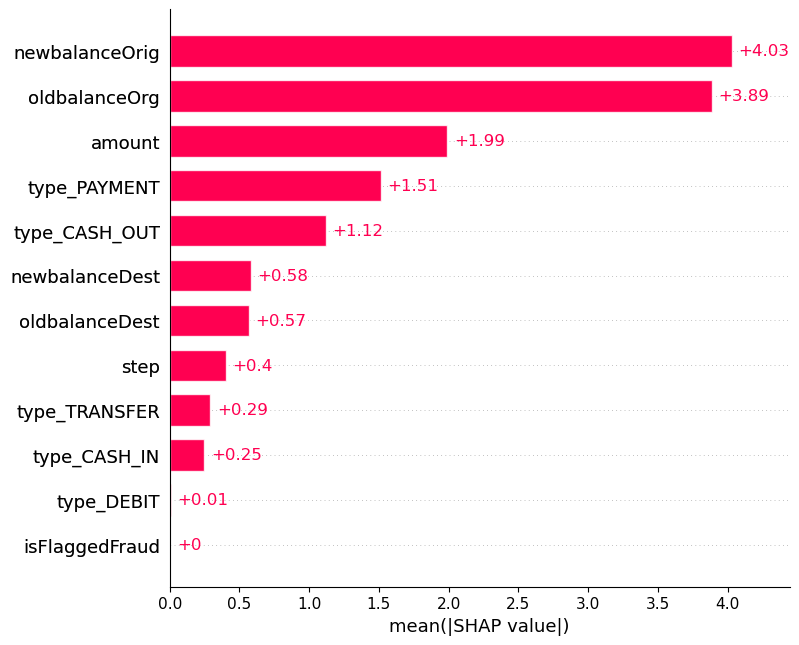

In [25]:
shap.plots.bar(
    shap_values,
    max_display=15
)

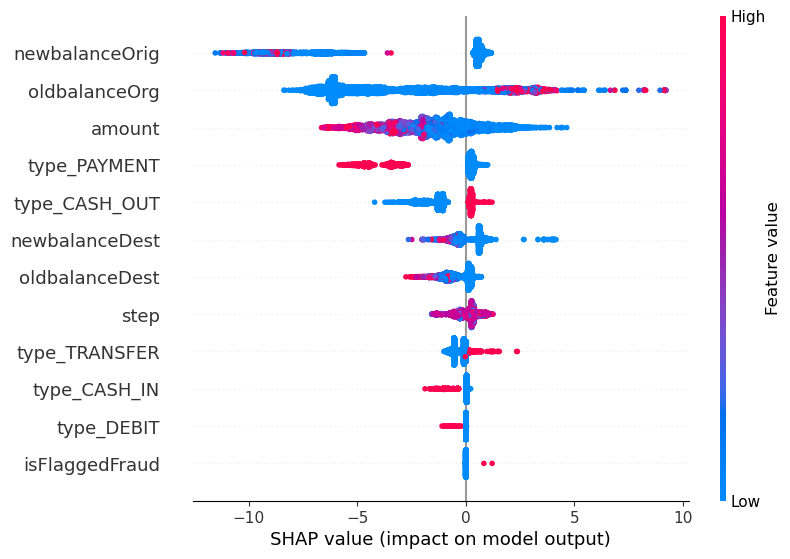

In [26]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

In [27]:
fraud_indices = np.where(
    y_test.loc[X_test_sample.index].values == 1
)[0]

print("Fraud transactions in sample:", len(fraud_indices))

Fraud transactions in sample: 63


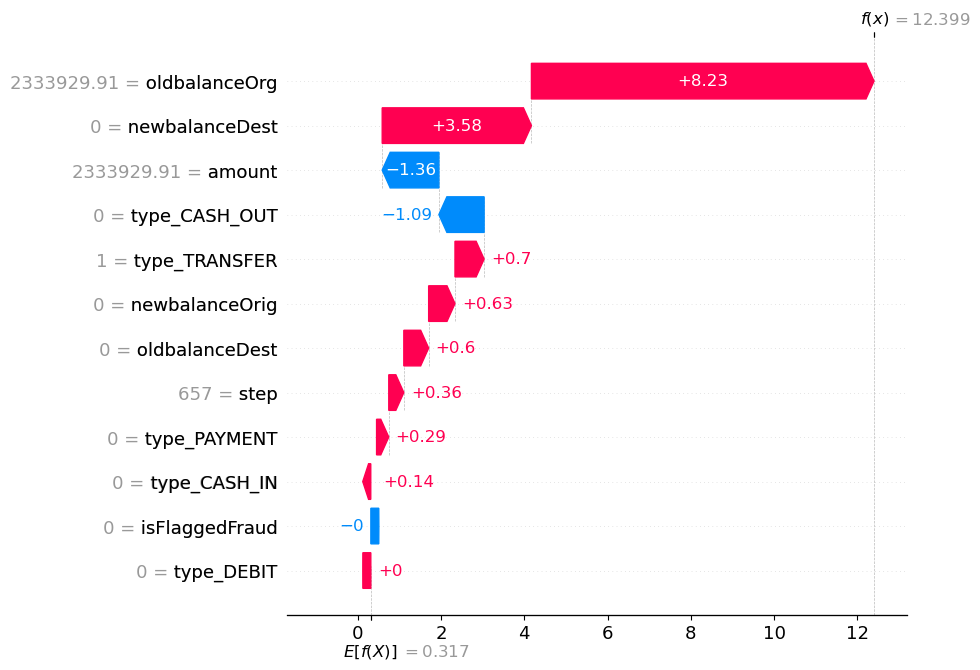

In [28]:
fraud_index = fraud_indices[0]

shap.plots.waterfall(
    shap_values[fraud_index],
    max_display=15
)

In [29]:
sample_probabilities = xgb_model.predict_proba(
    X_test_sample
)[:, 1]

sample_predictions = (
    sample_probabilities >= BEST_THRESHOLD
).astype(int)

sample_actual = y_test.loc[
    X_test_sample.index
].values

In [30]:
false_positive_indices = np.where(
    (sample_predictions == 1) &
    (sample_actual == 0)
)[0]

print(
    "False positives in sample:",
    len(false_positive_indices)
)

False positives in sample: 4


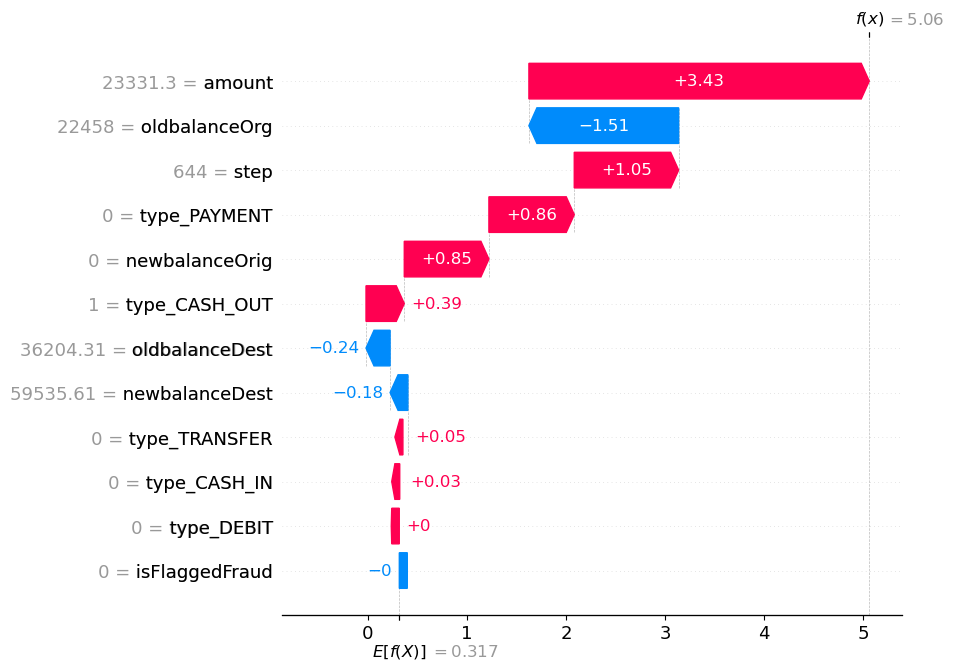

In [31]:
fp_index = false_positive_indices[0]

shap.plots.waterfall(
    shap_values[fp_index],
    max_display=15
)

In [32]:
false_negative_indices = np.where(
    (sample_predictions == 0) &
    (sample_actual == 1)
)[0]

print(
    "False negatives in sample:",
    len(false_negative_indices)
)

False negatives in sample: 4


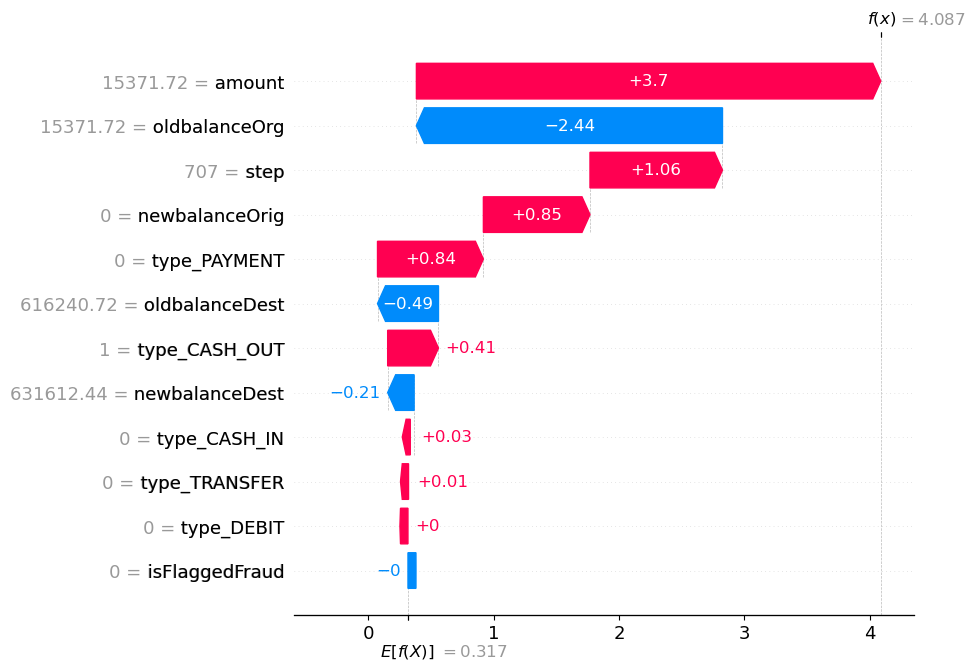

In [33]:
if len(false_negative_indices) > 0:

    fn_index = false_negative_indices[0]

    shap.plots.waterfall(
        shap_values[fn_index],
        max_display=15
    )

In [34]:
import shap

explainer = shap.TreeExplainer(xgb_model)

X_test_sample = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=42
)

shap_values = explainer(X_test_sample)

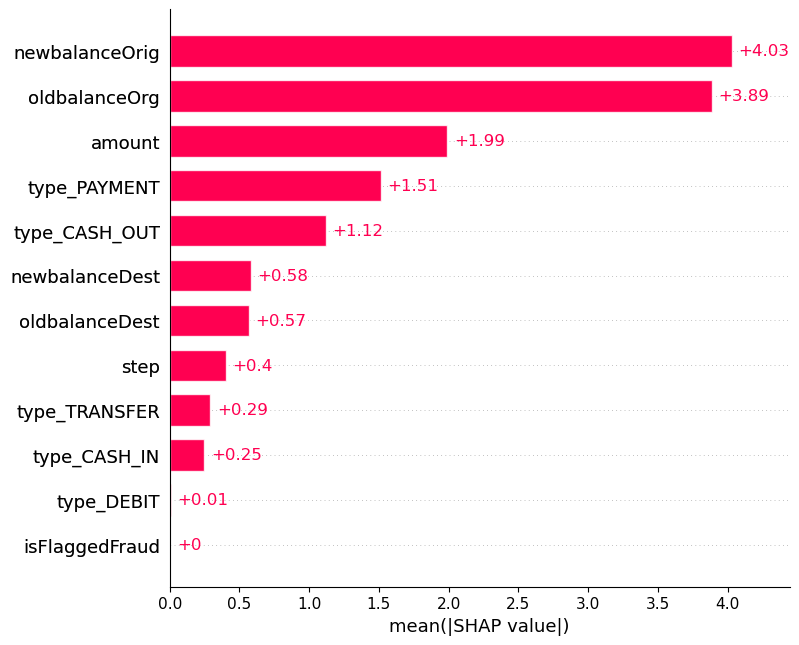

In [35]:
shap.plots.bar(
    shap_values,
    max_display=15
)

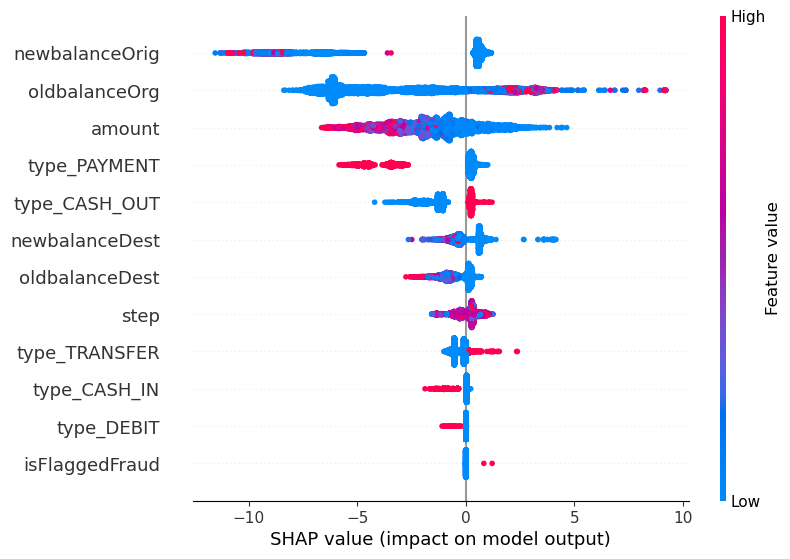

In [36]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

In [37]:
shap_importance = pd.DataFrame({
    "feature": X_test_sample.columns,
    "mean_abs_shap": np.abs(
        shap_values.values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
)

shap_importance.head(15)

,feature,mean_abs_shap
3,newbalanceOrig,4.030970
2,oldbalanceOrg,3.885375
1,amount,1.989729
10,type_PAYMENT,1.512333
8,type_CASH_OUT,1.121015
5,newbalanceDest,0.583388
4,oldbalanceDest,0.569161
0,step,0.403676
11,type_TRANSFER,0.289805
7,type_CASH_IN,0.248783


In [38]:
shap_importance.to_csv(
    "../data/processed/shap_feature_importance.csv",
    index=False
)